# Lab 9 — English → Gujarati Transformer NMT with pretrained embeddings (OpenNMT-py)

Same data and **same bin-stratified split as Lab 8** (ILCI subset of `ai4bharat/BPCC`, same seed, same code), but the Transformer is now initialised with **pretrained embeddings**:

| System | Units | Embeddings |
|---|---|---|
| `fasttext` | words | [fastText wiki vectors](https://fasttext.cc/docs/en/pretrained-vectors.html) (`wiki.en.vec`, `wiki.gu.vec`, 300-d) |
| `bpemb` | BPE subwords | [BPEmb](https://github.com/bheinzerling/bpemb) (`en` / `gu`, vocab 10k, 300-d) — text is first **encoded into subwords with BPEmb** |

**Pipeline:** load data → length bins → stratified split (identical to Lab 8) → tokenise per system → build vocab + embedding matrices → train with OpenNMT-py (`pre_word_vecs_enc/dec`) → translate → **bin-wise BLEU (sacreBLEU)** → compare → analysis.

> **Kaggle setup:** Accelerator **GPU T4 x2**, Internet **On**, `HF_TOKEN` secret added (BPCC is gated — accept the terms on its Hugging Face page). Then Save Version → *Save & Run All*. Expect ~1.5–2 h for both models.
> Tip: set `SMOKE_TEST = True` in section 3b first to check the whole pipeline in a few minutes.

## 1. Install

In [1]:
import os, sys, subprocess
ON_KAGGLE = os.path.exists("/kaggle/working")

# OpenNMT-py 3.5.1 needs torch<2.3 and pyonmttok, which have no wheels for Kaggle's Python 3.13,
# so on Kaggle the onmt_* commands run from a separate Python 3.11 env; this kernel does everything else.
pkgs = "sacrebleu sentencepiece huggingface_hub pandas pyarrow matplotlib pyyaml bpemb requests"
if ON_KAGGLE:
    ONMT_ENV = "/tmp/onmt_env"
    for cmd in [f"{sys.executable} -m pip install -q uv {pkgs}",
                f"{sys.executable} -m uv venv -q -p 3.11 {ONMT_ENV}",
                f"{sys.executable} -m uv pip install -q --python {ONMT_ENV}/bin/python OpenNMT-py==3.5.1 torch==2.2.2 'numpy<2'"]:
        subprocess.run(cmd, shell=True, check=True)
    ONMT = f"{ONMT_ENV}/bin/"
else:
    subprocess.run(f"{sys.executable} -m pip install -q OpenNMT-py {pkgs}", shell=True, check=True)
    ONMT = os.path.dirname(sys.executable) + "/"   # onmt_* live next to this kernel's python

print(subprocess.run(f"{ONMT}python -c \"import torch, onmt; print('OpenNMT-py', onmt.__version__, "
                     f"'| torch', torch.__version__, '| CUDA', torch.cuda.is_available())\"",
                     shell=True, check=True, capture_output=True, text=True).stdout)

try:
    import bpemb
    print("bpemb import OK")
except Exception as e:
    print("bpemb import failed -> the notebook will use its built-in fallback loader:", e)

OpenNMT-py 3.5.1 | torch 2.2.2 | CUDA False

bpemb import OK


## 2. Hugging Face login (dataset is gated)

In [2]:
from huggingface_hub import login
if ON_KAGGLE and not os.environ.get("HF_TOKEN"):
    from kaggle_secrets import UserSecretsClient   # Add-ons → Secrets → HF_TOKEN (ticked for this notebook)
    os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")
if os.environ.get("HF_TOKEN"):
    login(token=os.environ["HF_TOKEN"])
else:
    login()   # paste your HF access token (needs read access; you must have accepted the BPCC terms)

## 3. Configuration (same as Lab 8)

In [3]:
import os, random, glob, math, subprocess
import numpy as np, pandas as pd, torch

REPO          = "ai4bharat/BPCC"
TGT_LANG_CODE = "guj_Gujr"       # target language (change if your native language differs, e.g. hin_Deva, mar_Deva, ben_Beng)
TGT_NAME      = "Gujarati"
FILE_OVERRIDE = None             # set to a list of repo file paths if auto-discovery below picks the wrong files

# --- size limits (keeps everything small) ---
MAX_RAW_MB    = 500              # cap on raw text size used
MAX_PAIRS     = 200_000          # extra safety cap on number of sentence pairs

# --- splits ---
TEST_FRAC     = 0.10             # per-bin fraction for test
DEV_FRAC      = 0.02             # per-bin fraction (of the remainder) for validation
SEED          = 42

# --- model / training ---
SPM_VOCAB     = 8000
MAX_SPM_LEN   = 150              # drop training pairs longer than this (subword tokens)
TRAIN_STEPS   = 20000
VALID_STEPS   = 2000

WORK = "work"
os.makedirs(WORK, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
HAS_GPU = torch.cuda.is_available()
print("GPU available:", HAS_GPU)

GPU available: False


## 3b. Embedding-experiment settings
`EMB_DIM` must equal the Transformer width in OpenNMT-py (`word_vec_size == hidden_size`), so both systems use **d_model = 300** (heads = 6, 300 = 6 × 50).

In [4]:
EMB_DIM       = 300              # fastText wiki vectors are 300-d; BPEmb also ships d300 -> same d_model for both systems
HEADS, FF     = 6, 1200

FASTTEXT_LANG = {"src": "en", "tgt": "gu"}      # fastText wiki language codes (change "gu" if your target language differs)
FT_MAX_LINES  = {"src": 150_000, "tgt": 200_000}  # read only the most frequent words of each .vec (files are sorted by frequency)
FT_VOCAB      = {"src": 40_000, "tgt": 40_000}  # max word vocabulary per side for the fastText system
FT_MIN_FREQ   = 2                               # words seen < 2 times in train -> <unk>

BPEMB_LANG    = {"src": "en", "tgt": "gu"}      # BPEmb language codes
BPEMB_VS      = 10_000                          # BPEmb subword vocabulary size

FREEZE_EMB    = False                           # True: keep pretrained embeddings fixed; False: fine-tune them
RETRAIN       = False                           # False: skip training if checkpoints for that system already exist
EXPERIMENTS   = ["fasttext", "bpemb"]           # optional ablations: add "fasttext_random", "bpemb_random" (same tokens, random init)

SMOKE_TEST    = False                           # True: tiny run (~5 min) just to check that everything works
if SMOKE_TEST:
    TRAIN_STEPS, VALID_STEPS = 300, 150
    FT_MAX_LINES = {"src": 20_000, "tgt": 20_000}
    RETRAIN = True
print("experiments:", EXPERIMENTS, "| train steps:", TRAIN_STEPS)

experiments: ['fasttext', 'bpemb'] | train steps: 20000


## 4. Locate and load the ILCI data (English → target)

In [5]:
from huggingface_hub import HfApi, hf_hub_download
api = HfApi()

all_files = api.list_repo_files(REPO, repo_type="dataset")
lang3 = TGT_LANG_CODE.split("_")[0].lower()

if FILE_OVERRIDE:
    cand = FILE_OVERRIDE
else:
    cand = [f for f in all_files if "ilci" in f.lower() and lang3 in f.lower()]

if not cand:
    ilci_files = [f for f in all_files if "ilci" in f.lower()]
    print("No ILCI file matched the target language. ILCI files in the repo (first 60):")
    print("\n".join(ilci_files[:60]))
    raise SystemExit("Set FILE_OVERRIDE to the right file(s).")

infos = api.get_paths_info(REPO, cand, repo_type="dataset")
for i in infos:
    print(f"{i.path}  ({(getattr(i,'size',0) or 0)/1e6:.1f} MB)")

/opt/homebrew/Caskroom/miniconda/base/envs/illm_lab8/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ilci/guj_Gujr.tsv  (37.6 MB)


In [6]:
def pick_cols(df):
    lc = {c.lower(): c for c in df.columns}
    for a, b in [("src","tgt"),("src_text","tgt_text"),("source","target"),("en","gu"),("english","gujarati")]:
        if a in lc and b in lc:
            return lc[a], lc[b]
    obj = [c for c in df.columns if df[c].dtype == object]
    return obj[0], obj[1]

def read_one(path):
    local = hf_hub_download(REPO, path, repo_type="dataset")
    ext = path.lower().rsplit(".", 1)[-1]
    if ext == "parquet":            df = pd.read_parquet(local)
    elif ext in ("json", "jsonl"):
        try:                         df = pd.read_json(local, lines=True)
        except ValueError:           df = pd.read_json(local)
    elif ext == "csv":              df = pd.read_csv(local)
    elif ext == "tsv":              df = pd.read_csv(local, sep="\t")
    else: raise ValueError(f"Unsupported format: {path}")
    # if a file holds several language pairs, keep English -> target only
    if "tgt_lang" in df.columns and "src_lang" in df.columns:
        m = df["tgt_lang"].astype(str).str.startswith(lang3) & df["src_lang"].astype(str).str.startswith("eng")
        m_rev = df["src_lang"].astype(str).str.startswith(lang3) & df["tgt_lang"].astype(str).str.startswith("eng")
        s, t = pick_cols(df)
        out = pd.concat([df.loc[m, [s, t]].set_axis(["en","tgt"], axis=1),
                         df.loc[m_rev, [t, s]].set_axis(["en","tgt"], axis=1)])
        return out
    s, t = pick_cols(df)
    return df[[s, t]].set_axis(["en", "tgt"], axis=1)

def read_src_tgt_pairs(paths):
    """Handles layouts like train.src / train.tgt"""
    out = []
    srcs = [p for p in paths if p.endswith(".src")]
    for sp in srcs:
        tp = sp[:-4] + ".tgt"
        if tp in paths:
            a = open(hf_hub_download(REPO, sp, repo_type="dataset"), encoding="utf-8").read().split("\n")
            b = open(hf_hub_download(REPO, tp, repo_type="dataset"), encoding="utf-8").read().split("\n")
            n = min(len(a), len(b))
            out.append(pd.DataFrame({"en": a[:n], "tgt": b[:n]}))
    return out

frames = read_src_tgt_pairs(cand) if any(p.endswith(".src") for p in cand) else [read_one(p) for p in cand]
raw = pd.concat(frames, ignore_index=True)
print("Loaded pairs:", len(raw))
raw.head()

Loaded pairs: 107385


,en,tgt
0,What happened?,શું થયું ?
1,What’s the matter?,શું વાત છે ?
2,One gets Moksha with a visit to the Saptapuris !,સપ્તપુરીઓના દર્શનથી મળે છે મોક્ષ .
3,Pilgrimage is of utmost importance in Hinduism .,હિંદુધર્મમાં તીર્થનું ઘણું મહત્ત્વ છે .
4,Although all the pilgrimages are major and imp...,"આમ તો દરેક તીર્થ મહાન અને મહત્ત્વપૂર્ણ છે , પણ..."


## 5. Clean, cap to ~500 MB, compute lengths and bins

In [7]:
df = raw.dropna().copy()
df["en"]  = df["en"].astype(str).str.strip()
df["tgt"] = df["tgt"].astype(str).str.strip()
df = df[(df.en != "") & (df.tgt != "")]
df = df.drop_duplicates(subset=["en"]).drop_duplicates(subset=["tgt"]).reset_index(drop=True)

# length = number of whitespace-separated English words
df["len"]     = df["en"].str.split().str.len()
df["tgt_len"] = df["tgt"].str.split().str.len()
ratio = df["tgt_len"] / df["len"]
df = df[(df.len <= 100) & (ratio > 0.3) & (ratio < 3.0)].reset_index(drop=True)

# ---- size cap (~500 MB of raw text and MAX_PAIRS pairs) ----
raw_mb = (df.en.str.len().sum() + df.tgt.str.len().sum()) / 1e6
frac = min(1.0, MAX_RAW_MB / max(raw_mb, 1e-9), MAX_PAIRS / len(df))
if frac < 1.0:
    df = df.sample(frac=frac, random_state=SEED).reset_index(drop=True)
print(f"Raw text ≈ {raw_mb:.1f} MB -> keeping fraction {frac:.2f} -> {len(df):,} pairs")

# ---- the 4 bins ----
# bin1: <=10 | bin2: 11-20 | bin3: 21-29 | bin4: >=30
# (boundaries 20 and 30 are ambiguous in the handout; here 20 -> bin2, 30 -> bin4 so every length is covered)
def bin_of(n):
    if n <= 10: return "bin1"
    if n <= 20: return "bin2"
    if n < 30:  return "bin3"
    return "bin4"
df["bin"] = df["len"].apply(bin_of)
BINS = ["bin1", "bin2", "bin3", "bin4"]
print(df["bin"].value_counts().reindex(BINS))

Raw text ≈ 18.9 MB -> keeping fraction 1.00 -> 101,134 pairs
bin
bin1    18034
bin2    51398
bin3    22476
bin4     9226
Name: count, dtype: int64


## 6. Length-stratified train / dev / test split (identical to Lab 8)

       train   dev   test
bin                      
bin1   15906   325   1803
bin2   45333   925   5140
bin3   19823   405   2248
bin4    8137   166    923
total  89199  1821  10114


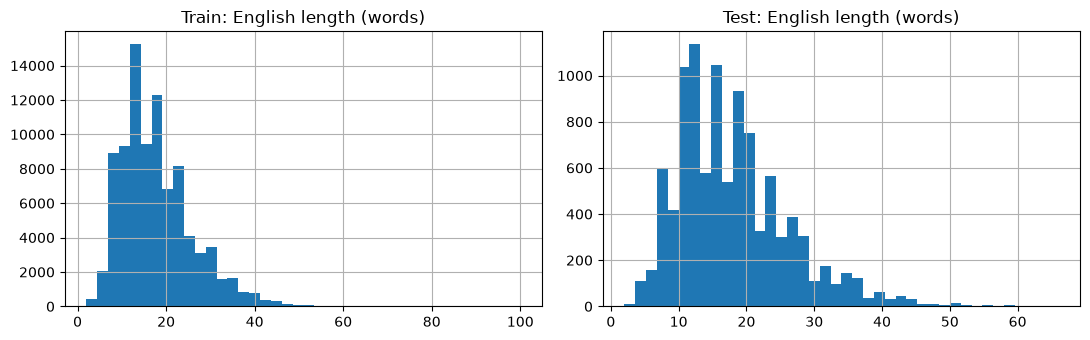

In [8]:
train_parts, dev_parts, test_parts = [], [], []
for b in BINS:
    g = df[df.bin == b].sample(frac=1.0, random_state=SEED)
    if len(g) < 20:
        print(f"WARNING: {b} has only {len(g)} sentences")
    n_test = max(1, int(round(len(g) * TEST_FRAC)))
    test_parts.append(g.iloc[:n_test])
    rest = g.iloc[n_test:]
    n_dev = max(1, int(round(len(rest) * DEV_FRAC)))
    dev_parts.append(rest.iloc[:n_dev])
    train_parts.append(rest.iloc[n_dev:])

train = pd.concat(train_parts).sample(frac=1.0, random_state=SEED).reset_index(drop=True)
dev   = pd.concat(dev_parts).sample(frac=1.0, random_state=SEED).reset_index(drop=True)
test  = pd.concat(test_parts).reset_index(drop=True)

summary = pd.DataFrame({
    "train": train.bin.value_counts(), "dev": dev.bin.value_counts(), "test": test.bin.value_counts()
}).reindex(BINS).fillna(0).astype(int)
summary.loc["total"] = summary.sum()
print(summary)

import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
train.len.hist(bins=40, ax=ax[0]); ax[0].set_title("Train: English length (words)")
test.len.hist(bins=40, ax=ax[1]);  ax[1].set_title("Test: English length (words)")
plt.tight_layout(); plt.show()

## 7. Tokenisation helpers for the two embedding types

* **fastText (word level):** whitespace split + punctuation separated; English is lower-cased (the wiki vectors are lower-cased). Frequent words become the NMT vocabulary; the rest → `<unk>`.
* **BPEmb (subword level):** every word is **encoded into BPE pieces with the BPEmb model** (`bpemb.encode`). BPEmb lower-cases text and maps *every digit to 0*, which would destroy numbers (and Gujarati digits) — so digits are kept as separate extra symbols and only the non-digit parts go through BPEmb. The vocabulary is exactly the BPEmb piece vocabulary (+ the digit symbols).

In [9]:
import re, string, collections, pickle, requests
from pathlib import Path

SPECIALS = ["<unk>", "<blank>", "<s>", "</s>"]     # OpenNMT-py default specials, in this order (ids 0..3)

# ---------------- word-level tokeniser (fastText system) ----------------
PUNCT = set(string.punctuation) | set("।॥“”‘’…–—«»")
def word_tok(s, lower=False):
    if lower: s = s.lower()
    out = []
    for w in s.split():
        pre, post = [], []
        while w and w[0] in PUNCT:  pre.append(w[0]);  w = w[1:]
        while w and w[-1] in PUNCT: post.append(w[-1]); w = w[:-1]
        out.extend(pre)
        if w: out.append(w)
        out.extend(reversed(post))
    return out

# ---------------- BPEmb subword encoder ----------------
DIGITS  = list("0123456789") + [chr(c) for c in range(0x0AE6, 0x0AF0)]    # ASCII + Gujarati digits
DIG_RE  = re.compile("([0-9\u0AE6-\u0AEF])")

def make_bpe_encoder(bp):
    cache = {}
    def enc_word(w):
        if w in cache: return cache[w]
        parts, out = [p for p in DIG_RE.split(w) if p], []
        for i, p in enumerate(parts):
            if DIG_RE.fullmatch(p):                    # digit: keep as its own symbol
                if i == 0: out.append("▁")             # word-start marker
                out.append(p)
            else:
                pcs = list(bp.encode(p))               # <- BPEmb subword encoding
                if i > 0 and pcs:                      # inside a word: drop the word-start marker
                    pcs[0] = pcs[0][1:] if pcs[0].startswith("▁") else pcs[0]
                    if pcs[0] == "": pcs = pcs[1:]
                out.extend(pcs)
        cache[w] = out
        return out
    def enc(s):
        out = []
        for w in s.split(): out.extend(enc_word(w))
        return out
    return enc

def bpe_decode(tokens):
    return "".join(tokens).replace("▁", " ").strip()

In [10]:
# ---------------- BPEmb loader (package if available, tiny fallback otherwise) ----------------
try:
    from bpemb import BPEmb
except Exception as e:
    BPEmb = None
    print("Using fallback BPEmb loader because the package could not be imported:", e)

def _download(url, path):
    import warnings
    from urllib3.exceptions import InsecureRequestWarning
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", InsecureRequestWarning)
        r = requests.get(url, stream=True, verify=False, timeout=120)
    r.raise_for_status()
    with open(path, "wb") as f:
        for chunk in r.iter_content(1 << 20): f.write(chunk)

class MiniBPEmb:
    """Minimal stand-in for bpemb.BPEmb (same files, no gensim needed)."""
    base = "https://nlp.h-its.org/bpemb/"
    def __init__(self, lang, vs, dim):
        import sentencepiece as spm, tarfile
        cache = Path(WORK) / "bpemb_cache"; cache.mkdir(parents=True, exist_ok=True)
        model = cache / f"{lang}.wiki.bpe.vs{vs}.model"
        tgz   = cache / f"{lang}.wiki.bpe.vs{vs}.d{dim}.w2v.bin.tar.gz"
        if not model.exists(): _download(f"{self.base}{lang}/{model.name}", model)
        if not tgz.exists():   _download(f"{self.base}{lang}/{tgz.name}", tgz)
        self.spm = spm.SentencePieceProcessor(model_file=str(model))
        with tarfile.open(tgz) as t:
            m = [x for x in t.getmembers() if x.name.endswith(".bin")][0]
            data = t.extractfile(m).read()
        nl = data.index(b"\n"); n, d = map(int, data[:nl].split()); pos = nl + 1
        pieces, vecs = [], np.empty((n, d), dtype=np.float32)
        for i in range(n):
            sp = data.index(b" ", pos)
            pieces.append(data[pos:sp].decode("utf-8").lstrip("\n"))
            vecs[i] = np.frombuffer(data, dtype=np.float32, count=d, offset=sp + 1)
            pos = sp + 1 + 4 * d
        self.pieces, self.vectors, self.dim = pieces, vecs, d
    def encode(self, text):
        return self.spm.EncodeAsPieces(text.lower())

BP = {}
def get_bpemb(side):
    if side not in BP:
        cls = BPEmb if BPEmb is not None else MiniBPEmb
        BP[side] = cls(lang=BPEMB_LANG[side], vs=BPEMB_VS, dim=EMB_DIM)
        print(f"BPEmb[{side}] lang={BPEMB_LANG[side]} vocab={len(BP[side].pieces)} dim={BP[side].vectors.shape[1]}")
    return BP[side]

# ---------------- fastText loader (streams only the top-N lines of the .vec file) ----------------
def load_fasttext(lang, max_lines):
    cache = Path(WORK) / f"ft_{lang}_{max_lines}.pkl"
    if cache.exists():
        return pickle.load(open(cache, "rb"))
    url = f"https://dl.fbaipublicfiles.com/fasttext/vectors-wiki/wiki.{lang}.vec"
    print("streaming", url, f"(first {max_lines:,} lines)")
    words, vecs = [], []
    with requests.get(url, stream=True, timeout=120) as r:
        r.raise_for_status()
        it = r.iter_lines(chunk_size=1 << 20, delimiter=b"\n")
        n_total, dim = map(int, next(it).decode().split())
        assert dim == EMB_DIM, f"fastText dim {dim} != EMB_DIM {EMB_DIM}"
        for i, line in enumerate(it):
            if i >= max_lines: break
            parts = line.decode("utf-8", errors="ignore").rstrip().split(" ")
            if len(parts) != dim + 1: continue
            words.append(parts[0]); vecs.append(np.asarray(parts[1:], dtype=np.float32))
            if (i + 1) % 50_000 == 0: print(f"  {i+1:,} lines")
    out = (words, np.vstack(vecs))
    pickle.dump(out, open(cache, "wb"))
    print(f"fastText[{lang}]: kept {len(words):,} of {n_total:,} vectors")
    return out

# ---------------- embedding matrix aligned with the OpenNMT vocabulary ----------------
def make_matrix(vocab, lookup, dim, seed=SEED):
    """Rows = SPECIALS + vocab (exactly OpenNMT's id order). Pretrained vectors are rescaled to the std of the
    default Transformer init (d**-0.5) because OpenNMT multiplies embeddings by sqrt(d); misses get random N(0, std)."""
    rng = np.random.default_rng(seed)
    std = dim ** -0.5
    M = rng.normal(0.0, std, size=(len(SPECIALS) + len(vocab), dim)).astype(np.float32)
    M[SPECIALS.index("<blank>")] = 0.0                      # padding row
    hit = []
    for i, tok in enumerate(vocab):
        v = lookup(tok)
        if v is not None:
            M[len(SPECIALS) + i] = v; hit.append(len(SPECIALS) + i)
    if hit:
        M[hit] *= std / M[hit].std()
    return torch.from_numpy(M), len(hit) / max(len(vocab), 1)

## 8. Prepare each system: tokenised corpora, vocabulary files, embedding matrices
Vocabulary files are written by us (not by `onmt_build_vocab`) so that row *i* of the embedding matrix is exactly OpenNMT's token id *i*. A check script run inside the OpenNMT environment verifies this alignment.

In [11]:
def write_lines(lines, path):
    with open(path, "w", encoding="utf-8") as f:
        f.write("\n".join(lines) + "\n")

CHECK_SCRIPT = """
import sys, pyonmttok
path, nrows = sys.argv[1], int(sys.argv[2])
toks = open(path, encoding="utf-8").read().split("\\n")[:-1]
sp = ["<unk>", "<blank>", "<s>", "</s>"]
v = pyonmttok.build_vocab_from_tokens(toks, maximum_size=0, special_tokens=sp)
bad = [t for i, t in enumerate(toks) if v[t] != i + len(sp)]
print("   OpenNMT vocab size", len(v), "| matrix rows", nrows, "| misaligned tokens", len(bad))
sys.exit(0 if (len(v) == nrows and not bad) else 1)
"""
open(f"{WORK}/check_vocab.py", "w").write(CHECK_SCRIPT)

def verify_alignment(vocab_path, nrows):
    r = subprocess.run(f"{ONMT}python {WORK}/check_vocab.py {vocab_path} {nrows}", shell=True, capture_output=True, text=True)
    print(r.stdout.strip() or r.stderr.strip()[-500:])
    assert r.returncode == 0, "embedding rows are not aligned with the OpenNMT vocabulary!"

PREP = {}

def prep(name):
    kind, pretrained = name.split("_")[0], not name.endswith("_random")
    d = f"{WORK}/{name}"
    os.makedirs(f"{d}/model", exist_ok=True); os.makedirs(f"{d}/onmt_run", exist_ok=True)
    splits = {"train": train, "dev": dev, "test": test}
    info = {"kind": kind, "pretrained": pretrained, "dir": d}

    # ---- 1) tokenise ----
    if kind == "fasttext":
        enc = {"src": lambda s: word_tok(s, lower=True), "tgt": lambda s: word_tok(s, lower=False)}
        info["detok"] = lambda s: s
    elif kind == "bpemb":
        enc = {"src": make_bpe_encoder(get_bpemb("src")), "tgt": make_bpe_encoder(get_bpemb("tgt"))}
        info["detok"] = lambda s: bpe_decode(s.split())
    else:
        raise ValueError(name)
    toks = {sp: (list(map(enc["src"], df.en)), list(map(enc["tgt"], df.tgt))) for sp, df in splits.items()}

    # ---- 2) vocabularies (+ embedding matrices) ----
    vocab, mats, cover = {}, {}, {}
    if kind == "fasttext":
        for si, side in enumerate(["src", "tgt"]):
            cnt = collections.Counter(t for sent in toks["train"][si] for t in sent)
            vocab[side] = [w for w, f in cnt.most_common() if f >= FT_MIN_FREQ and w not in SPECIALS][:FT_VOCAB[side]]
            covered = sum(cnt[w] for w in vocab[side]) / sum(cnt.values())
            cover[side] = {"vocab": len(vocab[side]), "train_token_coverage": round(covered, 4)}
            if pretrained:
                words, vecs = load_fasttext(FASTTEXT_LANG[side], FT_MAX_LINES[side])
                idx = {w: i for i, w in enumerate(words)}
                mats[side], hit = make_matrix(vocab[side], lambda t: vecs[idx[t]] if t in idx else None, EMB_DIM)
                cover[side]["vocab_with_pretrained_vector"] = round(hit, 4)
    else:
        for si, side in enumerate(["src", "tgt"]):
            bp = get_bpemb(side)
            pieces = [p for p in bp.pieces if p not in SPECIALS and p != "<pad>"]
            vocab[side] = list(dict.fromkeys(pieces + DIGITS))          # BPEmb pieces + digit symbols (deduplicated)
            cnt = collections.Counter(t for sent in toks["train"][si] for t in sent)
            vs = set(vocab[side])
            cover[side] = {"vocab": len(vocab[side]),
                           "train_token_coverage": round(sum(c for t, c in cnt.items() if t in vs) / sum(cnt.values()), 4),
                           "avg_pieces_per_sentence": round(np.mean([len(s) for s in toks["train"][si]]), 1)}
            if pretrained:
                pidx = {p: i for i, p in enumerate(bp.pieces)}
                mats[side], hit = make_matrix(vocab[side], lambda t: bp.vectors[pidx[t]] if t in pidx else None, EMB_DIM)
                cover[side]["vocab_with_pretrained_vector"] = round(hit, 4)

    # ---- 3) write files ----
    for side in ["src", "tgt"]:
        write_lines(vocab[side], f"{d}/vocab.{side}")
    keep = [i for i in range(len(toks["train"][0]))
            if 0 < len(toks["train"][0][i]) <= MAX_SPM_LEN and 0 < len(toks["train"][1][i]) <= MAX_SPM_LEN]
    write_lines([" ".join(toks["train"][0][i]) for i in keep], f"{d}/train.src")
    write_lines([" ".join(toks["train"][1][i]) for i in keep], f"{d}/train.tgt")
    write_lines([" ".join(t) for t in toks["dev"][0]],  f"{d}/dev.src")
    write_lines([" ".join(t) for t in toks["dev"][1]],  f"{d}/dev.tgt")
    write_lines([" ".join(t) for t in toks["test"][0]], f"{d}/test.src")
    if pretrained:
        for side, tag in [("src", "src"), ("tgt", "tgt")]:
            torch.save(mats[side], f"{d}/emb_{tag}.pt")

    print(f"[{name}] kept {len(keep):,}/{len(train):,} training pairs; coverage: {cover}")
    for side in ["src", "tgt"]:
        verify_alignment(f"{d}/vocab.{side}", len(SPECIALS) + len(vocab[side]))
    info.update(cover=cover, n_train=len(keep))
    PREP[name] = info

for name in EXPERIMENTS:
    prep(name)

streaming https://dl.fbaipublicfiles.com/fasttext/vectors-wiki/wiki.en.vec (first 150,000 lines)
  50,000 lines
  100,000 lines
  150,000 lines
fastText[en]: kept 150,000 of 2,519,370 vectors
streaming https://dl.fbaipublicfiles.com/fasttext/vectors-wiki/wiki.gu.vec (first 200,000 lines)
  50,000 lines
fastText[gu]: kept 74,632 of 74,632 vectors
[fasttext] kept 89,199/89,199 training pairs; coverage: {'src': {'vocab': 28628, 'train_token_coverage': 0.9837, 'vocab_with_pretrained_vector': 0.7415}, 'tgt': {'vocab': 40000, 'train_token_coverage': 0.9423, 'vocab_with_pretrained_vector': 0.588}}
OpenNMT vocab size 28632 | matrix rows 28632 | misaligned tokens 0
OpenNMT vocab size 40004 | matrix rows 40004 | misaligned tokens 0
downloading https://nlp.h-its.org/bpemb/en/en.wiki.bpe.vs10000.model


100%|██████████| 400869/400869 [00:00<00:00, 491659.24B/s]


downloading https://nlp.h-its.org/bpemb/en/en.wiki.bpe.vs10000.d300.w2v.bin.tar.gz


100%|██████████| 11189884/11189884 [00:07<00:00, 1490581.34B/s]


BPEmb[src] lang=en vocab=10000 dim=300
downloading https://nlp.h-its.org/bpemb/gu/gu.wiki.bpe.vs10000.model


100%|██████████| 466083/466083 [00:00<00:00, 662506.98B/s]


downloading https://nlp.h-its.org/bpemb/gu/gu.wiki.bpe.vs10000.d300.w2v.bin.tar.gz


100%|██████████| 11210876/11210876 [00:02<00:00, 4684599.96B/s]


BPEmb[tgt] lang=gu vocab=10000 dim=300
[bpemb] kept 89,193/89,199 training pairs; coverage: {'src': {'vocab': 10015, 'train_token_coverage': 0.9965, 'avg_pieces_per_sentence': 24.5, 'vocab_with_pretrained_vector': 0.9982}, 'tgt': {'vocab': 10006, 'train_token_coverage': 0.9972, 'avg_pieces_per_sentence': 24.6, 'vocab_with_pretrained_vector': 0.9991}}
OpenNMT vocab size 10019 | matrix rows 10019 | misaligned tokens 0
OpenNMT vocab size 10010 | matrix rows 10010 | misaligned tokens 0


## 9. Train the Transformer (OpenNMT-py) with pretrained embeddings

In [12]:
def write_cfg(name):
    info = PREP[name]; d = info["dir"]
    cfg = {
        "save_data": f"{d}/onmt_run/example",
        "src_vocab": f"{d}/vocab.src", "tgt_vocab": f"{d}/vocab.tgt",
        "src_vocab_size": 200000, "tgt_vocab_size": 200000, "vocab_size_multiple": 1,   # keep vocab == embedding matrix rows
        "overwrite": True,
        "data": {
            "corpus_1": {"path_src": f"{d}/train.src", "path_tgt": f"{d}/train.tgt"},
            "valid":    {"path_src": f"{d}/dev.src",   "path_tgt": f"{d}/dev.tgt"},
        },
        "save_model": f"{d}/model/nmt", "save_checkpoint_steps": VALID_STEPS, "keep_checkpoint": 3,
        "seed": SEED, "train_steps": TRAIN_STEPS, "valid_steps": VALID_STEPS,
        "warmup_steps": 4000 if not SMOKE_TEST else 100, "report_every": 500, "early_stopping": 5,
        "world_size": 1, "gpu_ranks": [0] if HAS_GPU else [],
        "model_dtype": "fp16" if HAS_GPU else "fp32",

        "decoder_type": "transformer", "encoder_type": "transformer", "position_encoding": True,
        "enc_layers": 4, "dec_layers": 4, "heads": HEADS,
        "hidden_size": EMB_DIM, "word_vec_size": EMB_DIM, "transformer_ff": FF,
        "dropout_steps": [0], "dropout": [0.1], "attention_dropout": [0.1],

        "optim": "adam", "adam_beta2": 0.998, "decay_method": "noam",
        "learning_rate": 2.0, "max_grad_norm": 0.0, "label_smoothing": 0.1,
        "param_init": 0.0, "param_init_glorot": True, "normalization": "tokens",
        "batch_type": "tokens", "batch_size": 4096, "valid_batch_size": 2048,
        "accum_count": [2], "accum_steps": [0], "max_generator_batches": 2,
    }
    if info["pretrained"]:
        cfg["pre_word_vecs_enc"] = f"{d}/emb_src.pt"       # encoder (English) embeddings
        cfg["pre_word_vecs_dec"] = f"{d}/emb_tgt.pt"       # decoder (target) embeddings
        if FREEZE_EMB:                                      # store_true flags: only pass them when True
            cfg["freeze_word_vecs_enc"] = True
            cfg["freeze_word_vecs_dec"] = True
    with open(f"{d}/config.yaml", "w") as f:
        yaml.safe_dump(cfg, f, sort_keys=False)

def ckpts_of(name):
    return sorted(glob.glob(f"{PREP[name]['dir']}/model/nmt_step_*.pt"),
                  key=lambda p: int(p.rsplit("_", 1)[1].split(".")[0]))

import yaml
for name in EXPERIMENTS:
    print("\n" + "=" * 20, "TRAINING:", name, "=" * 20)
    if ckpts_of(name) and not RETRAIN:
        print("checkpoints found -> skipping (set RETRAIN = True to train again):", ckpts_of(name)[-1]); continue
    write_cfg(name)
    get_ipython().system(f"{ONMT}onmt_train -config {PREP[name]['dir']}/config.yaml")
    assert ckpts_of(name), f"training of {name} produced no checkpoint - check the log above"


==================== TRAINING: fasttext ====================
[2026-10-23 14:02:51,149 INFO] Missing transforms field for corpus_1 data, set to default: [].
[2026-10-23 14:02:51,150 WARNING] Corpus corpus_1's weight should be given. We default it to 1 for you.
[2026-10-23 14:02:51,150 INFO] Missing transforms field for valid data, set to default: [].
[2026-10-23 14:02:51,150 INFO] Parsed 2 corpora from -data.
[2026-10-23 14:02:51,150 INFO] Get special vocabs from Transforms: {'src': [], 'tgt': []}.
[2026-10-23 14:02:51,180 INFO] The first 10 tokens of the vocabs are:['<unk>', '<blank>', '<s>', '</s>', 'the', '.', 'of', ',', 'in', 'and']
[2026-10-23 14:02:51,180 INFO] The decoder start token is: <s>
[2026-10-23 14:02:51,180 INFO] Building model...
[2026-10-23 14:02:51,524 INFO] Switching model to float32 for amp/apex_amp
[2026-10-23 14:02:51,524 INFO] Non quantized layer compute is fp32
[2026-10-23 14:02:51,525 INFO] NMTModel(
  (encoder): TransformerEncoder(
    (embeddings): Embedding

AssertionError: training of fasttext produced no checkpoint - check the log above

## 10. Translate the test set

In [ ]:
HYPS, UNK_RATE = {}, {}
gpu_flag = "-gpu 0" if HAS_GPU else ""
for name in EXPERIMENTS:
    d, ck = PREP[name]["dir"], ckpts_of(name)[-1]
    print(f"\n[{name}] checkpoint: {ck}")
    get_ipython().system(f"{ONMT}onmt_translate -model {ck} -src {d}/test.src -output {d}/test.pred "
                         f"{gpu_flag} -beam_size 5 -batch_size 64 -max_length 200")
    lines = open(f"{d}/test.pred", encoding="utf-8").read().split("\n")[:len(test)]
    assert len(lines) == len(test), "number of translations != number of test sentences"
    toks = [t for l in lines for t in l.split()]
    UNK_RATE[name] = sum(t == "<unk>" for t in toks) / max(len(toks), 1)
    HYPS[name] = [PREP[name]["detok"](l) for l in lines]
    print(f"[{name}] <unk> rate in output: {UNK_RATE[name]*100:.2f}%")

T = test[["en", "tgt", "len", "bin"]].copy()
for name in EXPERIMENTS: T[name] = HYPS[name]
T.head()

## 11. Bin-wise BLEU with sacreBLEU

In [ ]:
import sacrebleu
from sacrebleu.metrics import BLEU, CHRF

def bleu_obj(tok):
    try:    return BLEU(tokenize=tok, force=True)
    except Exception as e:
        print(f"tokenizer '{tok}' unavailable ({e}); skipping"); return None

bleu_13a  = BLEU(force=True)               # default sacreBLEU (13a); force=True: our hypotheses/refs mix tokenised and raw punctuation
bleu_f200 = bleu_obj("flores200")          # SPM-based; better suited to Indic scripts
chrf      = CHRF(word_order=2)             # chrF++ (extra cross-check)

def score_block(d, col):
    hyps, refs = d[col].tolist(), [d["tgt"].tolist()]
    r = bleu_13a.corpus_score(hyps, refs)
    row = {"n_sent": len(d), "BLEU(13a)": r.score, "BP": r.bp, "len_ratio": r.sys_len / max(r.ref_len, 1),
           "chrF++": chrf.corpus_score(hyps, refs).score}
    if bleu_f200: row["BLEU(flores200)"] = bleu_f200.corpus_score(hyps, refs).score
    return row

RESULTS = {}
for name in EXPERIMENTS:
    rows = {b: score_block(T[T.bin == b], name) for b in BINS}
    rows["overall"] = score_block(T, name)
    RESULTS[name] = pd.DataFrame(rows).T
    print(f"\n=== {name} ===")
    display(RESULTS[name].round(2))

In [ ]:
# ---- side-by-side comparison (BLEU, default sacreBLEU 13a tokenisation) ----
LAB8_REF = {"bin1": 19.15, "bin2": 15.12, "bin3": 12.89, "bin4": 10.82, "overall": 14.07}   # your Lab 8 result (SentencePiece 8k, random init); set to None to hide

cmp13 = pd.DataFrame({n: RESULTS[n]["BLEU(13a)"] for n in EXPERIMENTS})
if LAB8_REF: cmp13["Lab8 (SPM, random emb)"] = pd.Series(LAB8_REF)
print("BLEU (13a):");  display(cmp13.astype(float).round(2))

if bleu_f200:
    cmpf = pd.DataFrame({n: RESULTS[n]["BLEU(flores200)"] for n in EXPERIMENTS})
    print("BLEU (flores200 tokenizer):");  display(cmpf.astype(float).round(2))
print("chrF++:");  display(pd.DataFrame({n: RESULTS[n]["chrF++"] for n in EXPERIMENTS}).astype(float).round(2))

fig, axes = plt.subplots(1, 2 if bleu_f200 else 1, figsize=(12 if bleu_f200 else 6.5, 4), squeeze=False)
for ax, (title, tab) in zip(axes[0], [("BLEU (13a)", cmp13)] + ([("BLEU (flores200)", cmpf)] if bleu_f200 else [])):
    tab.astype(float).plot.bar(ax=ax, rot=0); ax.set_title(f"{title} per length bin (EN → {TGT_NAME})"); ax.set_ylabel("BLEU")
plt.tight_layout(); plt.show()

## 12. Analysis helpers

In [ ]:
for name in EXPERIMENTS:
    R = RESULTS[name]; col = "BLEU(13a)"
    best, worst = R.loc[BINS, col].astype(float).idxmax(), R.loc[BINS, col].astype(float).idxmin()
    print(f"\n#### {name}")
    print(f"best bin {best} ({R.loc[best, col]:.2f}) | worst bin {worst} ({R.loc[worst, col]:.2f}) | "
          f"bin1→bin4 drop: {R.loc['bin1', col] - R.loc['bin4', col]:.2f} BLEU")
    print(f"<unk> rate in translations: {UNK_RATE[name]*100:.2f}%")
    print("length ratio / brevity penalty per bin:"); print(R.loc[BINS, ["len_ratio", "BP"]].astype(float).round(3).T.to_string())
    print("vocabulary / embedding coverage:", PREP[name]["cover"])

print("\nTraining-data share per bin (%):"); print((train.bin.value_counts(normalize=True).reindex(BINS) * 100).round(1).to_string())

# gain of each system over the other, per bin
if len(EXPERIMENTS) >= 2:
    a, b = EXPERIMENTS[0], EXPERIMENTS[1]
    print(f"\nBLEU({b}) - BLEU({a}) per bin:")
    print((cmp13[b].astype(float) - cmp13[a].astype(float)).round(2).to_string())

# sentence-level chrF++ per bin
for name in EXPERIMENTS:
    T[f"chrf_{name}"] = [chrf.sentence_score(h, [r]).score for h, r in zip(T[name], T.tgt)]
print("\nMean sentence-level chrF++ per bin:")
print(T.groupby("bin")[[f"chrf_{n}" for n in EXPERIMENTS]].mean().reindex(BINS).round(2).to_string())

# examples
for b in BINS:
    print(f"\n===== {b} =====")
    for _, r in T[T.bin == b].sample(2, random_state=SEED).iterrows():
        print("SRC:", r.en); print("REF:", r.tgt)
        for n in EXPERIMENTS: print(f"{n.upper():>8}:", r[n])
        print()

In [ ]:
for name in EXPERIMENTS:
    RESULTS[name].round(3).to_csv(f"{WORK}/binwise_results_{name}.csv")
cmp13.round(3).to_csv(f"{WORK}/binwise_comparison_bleu13a.csv")
T[["en", "tgt", "len", "bin"] + EXPERIMENTS].to_csv(f"{WORK}/test_predictions_lab9.csv", index=False)
print("saved results + predictions in", WORK)

## 13. Result analysis (fill in after running)

**Setup:** English → Gujarati, ILCI subset of BPCC (same bin-stratified split as Lab 8), Transformer (4+4 layers, d=300, 6 heads) in OpenNMT-py, embeddings initialised from (1) fastText wiki vectors (word level) and (2) BPEmb subword vectors (BPE pieces, 10k vocab); beam 5; bins by English word count: bin1 ≤10, bin2 11–20, bin3 21–29, bin4 ≥30.

**Table:** paste the bin-wise BLEU table from section 11.

**Points to discuss (use your numbers):**
1. **Trend across bins** – does BLEU fall with sentence length for both embedding types? Compare bin1 vs bin4 for each.
2. **fastText vs BPEmb** – which is better overall and per bin? Link it to the unit: word level has a closed vocabulary (`<unk>` rate, rare/inflected Gujarati words, sparse softmax) while BPE subwords handle rare words but make sequences longer (harder for long sentences).
3. **Effect of pretraining** – compare with Lab 8 (SentencePiece, random init) and, if you ran them, the `*_random` ablations. The `_random` runs isolate pretraining from tokenisation.
4. **Embedding coverage** – fraction of the vocabulary that received a pretrained vector (section 8); low coverage on the Gujarati side limits the benefit of fastText.
5. **Brevity penalty / length ratio** – are long-sentence translations too short?
6. **Qualitative errors** – from the examples: `<unk>` tokens, wrong inflections, dropped clauses, numbers.
7. **Limitations & improvements** – small in-domain data, BLEU's weakness on a morphologically rich language (chrF++ cross-check), fine-tune vs freeze embeddings, larger BPEmb vocabulary (25k), more data, back-translation.